# PPMI Modality Analysis: Medical History, Diagnostics & Medications
**Notebook**: `eda_pca_medical.ipynb`  
**Modality Group**: `medical` (9 Scoped Analyzable Units)  
**Authoritative Scope**: `docs/important_modality_files.md`  
**Cohort Policy (Revision 4)**: Parkinson's disease (`PD`) and Healthy Controls (`HC`) Only  
**PCA Architecture**: Shared-space class-balanced component space fit on 1 deterministic record per participant  
**Governance Framework**: Codex Supervisory Review & `AGENTS.md` Task `EDA-PCA-001`  

---

## Modality Overview
Levodopa Equivalent Daily Dose (LEDD), concomitant medications, MedDRA medical condition logs, vital signs, freezing and falls, general physical and neurological exams, and diagnostic certainty logs.

### Scientific & Governance Invariants
1. **Target Cohort Restriction**: Analytical populations and PCA models are restricted exclusively to verified **Parkinson's disease (`PD`)** and **Healthy Controls (`HC`)**. Excluded classes (SWEDD, prodromal, genetic non-motor carriers) are filtered out prior to analysis. Cohort labels and disease staging fields never enter the PCA feature matrix.
2. **Participant-Level Shared-Space PCA**: For eligible participant-level tables, repeated visits are resolved to 1 record per participant (baseline preferred with stable tie-breaking and completeness checks). PCA and preprocessing (median imputation, scaling) are fit exclusively on a shared, deterministically class-balanced sample ($k = \min(N_{PD}, N_{HC})$, sampled via SHA-256 hash ranking) to reduce direct sample-count influence on component orientation, and all target participants are projected into this identical space.
3. **Comprehensive Committed EDA (Correction C1 / R4-02)**: Exact schemas with variable roles, missingness, duplicate rows, observation grain, numeric skewness, Tukey IQR and z-score outlier metrics, and categorical frequency summaries are visibly rendered in this notebook and committed directly to disk.
4. **Privacy-Safe Displays (Correction C3 / R4-05)**: Scree plots, loadings tables, and 2x2 side-by-side PD vs HC hexbin density score plots with cell suppression ($< 5$ observations masked) and outlier disclosures.
5. **Committed State Reproducibility (Correction C4 / R4-04)**: Loads directly from committed reports (`EDA/outputs/reports/`) using repository-relative POSIX paths with zero dependence on ignored cache.

In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 10

# Resolve repository root
repo_root = Path.cwd().resolve()
if (repo_root / "EDA" / "src").exists():
    sys.path.insert(0, str(repo_root / "EDA" / "src"))
elif (repo_root.parent / "EDA" / "src").exists():
    repo_root = repo_root.parent
    sys.path.insert(0, str(repo_root / "EDA" / "src"))

from ppmi_pipeline.reporting.privacy import PrivacyGuard

print(f"Environment initialized. Modality: 'medical', Dynamic repository root: ppmi")

Environment initialized. Modality: 'medical', Dynamic repository root: ppmi


## 1. Scoped Analyzable Units in Medical History, Diagnostics & Medications
The authoritative catalog assigns exactly **9 analyzable unit(s)** to this modality domain.

In [2]:
manifest_path = repo_root / "EDA" / "outputs" / "reports" / "priority_eda_pca_manifest.json"
with open(manifest_path, "r", encoding="utf-8") as f:
    manifest_data = json.load(f)

mod_units = [u for u in manifest_data["units"] if u.get("modality_group") == 'medical']

inv_rows = []
for unit_entry in mod_units:
    sheet_suffix = (" -> [" + str(unit_entry.get("sheet_name")) + "]") if unit_entry.get("sheet_name") else ""
    pca_stat_str = ("COMPLETED (" + str(unit_entry.get("pca_included_features_count", 0)) + " feats)") if unit_entry.get("pca_status") == "COMPLETED" else str(unit_entry.get("pca_skip_reason"))
    inv_rows.append({
        "Unit Slug": unit_entry["unit_slug"],
        "Filename / Sheet": str(unit_entry.get("declared_filename")) + sheet_suffix,
        "Physical Exists": "Yes" if unit_entry.get("physical_exists") else "No (Absent)",
        "EDA Status": unit_entry.get("eda_status"),
        "PCA Status": unit_entry.get("pca_status"),
        "PCA Reason / Features": pca_stat_str
    })

inv_df = pd.DataFrame(inv_rows)
display(inv_df)
print(f"Total units cataloged: {len(inv_df)} | EDA Completed: {(inv_df['EDA Status'] == 'COMPLETED').sum()} | PCA Completed: {(inv_df['PCA Status'] == 'COMPLETED').sum()}")

,Unit Slug,Filename / Sheet,Physical Exists,EDA Status,PCA Status,PCA Reason / Features
0,MEDICAL_HISTORY_LEDD_Concomitant_Medication_Lo...,LEDD_Concomitant_Medication_Log_09Nov2026.csv,Yes,COMPLETED,SKIPPED,Inadequate initial participant count for multi...
1,MEDICAL_HISTORY_Concomitant_Medication_Log_09N...,Concomitant_Medication_Log_09Nov2026.csv,Yes,COMPLETED,SKIPPED,Insufficient usable numeric analytical feature...
2,MEDICAL_HISTORY_Medical_Conditions_Log_09Nov20...,Medical_Conditions_Log_09Nov2026.csv,Yes,COMPLETED,SKIPPED,Insufficient usable numeric analytical feature...
3,MEDICAL_HISTORY_Vital_Signs_09Nov2026_csv,Vital_Signs_09Nov2026.csv,Yes,COMPLETED,COMPLETED,COMPLETED (7 feats)
4,MEDICAL_HISTORY_Primary_Research_Diagnosis_09N...,Primary_Research_Diagnosis_09Nov2026.csv,Yes,COMPLETED,SKIPPED,Insufficient usable numeric analytical feature...
5,MEDICAL_HISTORY_Clinical_Diagnosis_09Nov2026_csv,Clinical_Diagnosis_09Nov2026.csv,Yes,COMPLETED,SKIPPED,Insufficient usable numeric analytical feature...
6,MEDICAL_HISTORY_Determination_of_Freezing_and_...,Determination_of_Freezing_and_Falls_09Nov2026.csv,Yes,COMPLETED,COMPLETED,COMPLETED (4 feats)
7,MEDICAL_HISTORY_General_Physical_Exam_09Nov202...,General_Physical_Exam_09Nov2026.csv,Yes,COMPLETED,SKIPPED,Insufficient usable numeric analytical feature...
8,MEDICAL_HISTORY_Neurological_Exam_09Nov2026_csv,Neurological_Exam_09Nov2026.csv,Yes,COMPLETED,COMPLETED,COMPLETED (5 feats)


Total units cataloged: 9 | EDA Completed: 9 | PCA Completed: 3


---
## 2.1. Unit: `LEDD_Concomitant_Medication_Log_09Nov2026.csv` 
- **Unit Slug**: `MEDICAL_HISTORY_LEDD_Concomitant_Medication_Log_09Nov2026_csv`
- **Source Path**: `MEDICAL HISTORY/LEDD_Concomitant_Medication_Log_09Nov2026.csv`
- **Committed Unit Artifact**: [`MEDICAL_HISTORY_LEDD_Concomitant_Medication_Log_09Nov2026_csv.json`](../EDA/outputs/reports/units/MEDICAL_HISTORY_LEDD_Concomitant_Medication_Log_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, START_DATE, DRUG_NAME)`
- **Selection Tier**: `Supporting` | **Role**: `Standardized **Levodopa Equivalent Daily Dose (LEDD)** calculations. Crucial covariate for adjusting UPDRS motor scores to account for dopaminergic symptom masking.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `SKIPPED`

UNIT ANALYSIS: MEDICAL HISTORY/LEDD_Concomitant_Medication_Log_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: SKIPPED
Dimensions: 9,614 analyzed rows x 16 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 10,373 (1,891 participants)
  - PD Retained:  9,608 rows (1,543 participants)
  - HC Retained:  6 rows (4 participants)
  - Non-Target Excluded: 571 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  188 rows

Exact Variable Schema & Storage Types (16 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"9,614",Identifier
1,PATNO,int64,0,0.0%,"1,547",Identifier
2,EVENT_ID,object,0,0.0%,2,Identifier
3,PAG_NAME,object,0,0.0%,2,Administrative Metadata
4,LEDTRT,object,0,0.0%,797,Date / Timestamp / Visit
5,TOTDDA,float64,"9,577",99.6%,35,Analytical Numeric Measurement
6,LEDDSTRMG,float64,"4,861",50.6%,53,Analytical Numeric Measurement
7,LEDDOSSTR,object,"4,861",50.6%,69,Categorical / Text
8,LEDDOSE,float64,"4,849",50.4%,27,Analytical Numeric Measurement
9,LEDDOSFRQ,float64,"4,849",50.4%,11,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,4
Date / Timestamp / Visit,4
Identifier,3
Administrative Metadata,2
Categorical / Text,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 31,697 / 153,824 (20.61%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (8 total, top 8):


,name,missing_count,missing_percent,variable_role
5,TOTDDA,"9,577",99.6%,Analytical Numeric Measurement
6,LEDDSTRMG,"4,861",50.6%,Analytical Numeric Measurement
7,LEDDOSSTR,"4,861",50.6%,Categorical / Text
8,LEDDOSE,"4,849",50.4%,Analytical Numeric Measurement
9,LEDDOSFRQ,"4,849",50.4%,Analytical Numeric Measurement
11,STOPDT,"2,581",26.9%,Date / Timestamp / Visit
12,LEDD,96,1.0%,Categorical / Text
13,ORIG_ENTRY,23,0.2%,Administrative Metadata


... (2 outputs left out)

  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"9,608"
1,HC,6



Numeric Summaries & Outlier Diagnostics (4 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,TOTDDA,921.198,1029.489,0.190,430.0,3364.0,0.854,Moderately skewed (positive),0,0
1,LEDDSTRMG,95.600,65.301,0.088,100.0,350.0,0.516,Moderately skewed (positive),700,14
2,LEDDOSE,1.472,17.493,0.250,1.0,1208.0,68.904,Strongly skewed (positive),"1,560",1
3,LEDDOSFRQ,2.449,1.403,1.000,2.0,12.0,0.988,Moderately skewed (positive),40,40


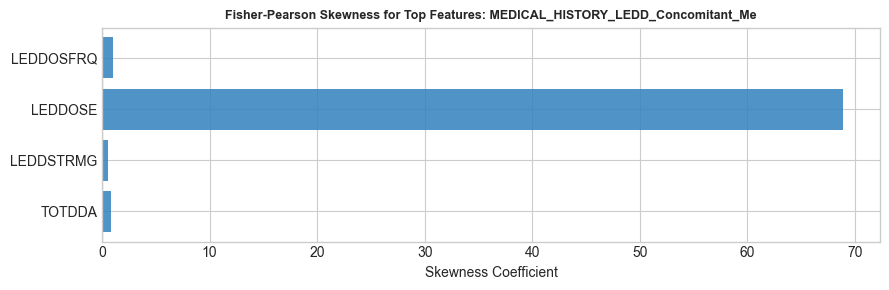

In [3]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "MEDICAL_HISTORY_LEDD_Concomitant_Medication_Log_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: MEDICAL HISTORY/LEDD_Concomitant_Medication_Log_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to MEDICAL_HISTORY_LEDD_Concomitant_Medication_Log_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in MEDICAL_HISTORY_LEDD_Concomitant_Medication_Log_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: MEDICAL_HISTORY_LEDD_Concomitant_Me", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Deterministic Skip
- **Status**: `SKIPPED`
- **Deterministic Skip Reason**: `Inadequate initial participant count for multivariate PCA (< 10 participants in target cohort)`
- **Methodological Justification**: This dataset does not meet the scientific prerequisites for multivariate PCA (e.g. lacks $\ge 2$ continuous analytical measurements, is an unpivoted single-measurement log, represents cell repository inventory, or lacks adequate two-class participant coverage).

In [4]:
pca_res = unit_data.get("pca_results") or {}
skip_reason = pca_res.get("skip_reason") or unit_data.get("pca_skip_reason")
print(f"PCA Skip Reason: {skip_reason}")
print(f"Features Evaluated: {pca_res.get('feature_count', 0)} included, {pca_res.get('excluded_features_count', 0)} excluded")
if pca_res.get("excluded_features"):
    ex_df = pd.DataFrame(pca_res["excluded_features"][:10])
    print("\nExcluded Variables Sample:")
    display(ex_df)

PCA Skip Reason: Inadequate initial participant count for multivariate PCA (< 10 participants in target cohort)
Features Evaluated: 0 included, 0 excluded


---
## 2.2. Unit: `Concomitant_Medication_Log_09Nov2026.csv` 
- **Unit Slug**: `MEDICAL_HISTORY_Concomitant_Medication_Log_09Nov2026_csv`
- **Source Path**: `MEDICAL HISTORY/Concomitant_Medication_Log_09Nov2026.csv`
- **Committed Unit Artifact**: [`MEDICAL_HISTORY_Concomitant_Medication_Log_09Nov2026_csv.json`](../EDA/outputs/reports/units/MEDICAL_HISTORY_Concomitant_Medication_Log_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, LOG_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Comprehensive medication history recording drug trade/generic names, indication, daily dose, unit, route, and start/end dates.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `SKIPPED`

UNIT ANALYSIS: MEDICAL HISTORY/Concomitant_Medication_Log_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: SKIPPED
Dimensions: 24,052 analyzed rows x 23 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 68,820 (7,834 participants)
  - PD Retained:  20,022 rows (1,593 participants)
  - HC Retained:  4,030 rows (312 participants)
  - Non-Target Excluded: 28,986 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  15,782 rows

Exact Variable Schema & Storage Types (23 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"24,052",Identifier
1,PATNO,int64,0,0.0%,"1,905",Identifier
2,EVENT_ID,object,0,0.0%,2,Identifier
3,PAG_NAME,object,0,0.0%,2,Administrative Metadata
4,CMTRT,object,0,0.0%,"8,146",Categorical / Text
5,CMDOSE,float64,"12,145",50.5%,284,Analytical Numeric Measurement
6,CMDOSU,object,"12,123",50.4%,172,Categorical / Text
7,CMDOSFRQ,object,"12,075",50.2%,345,Categorical / Text
8,ROUTE,float64,"12,066",50.2%,9,Analytical Numeric Measurement
9,STARTDT,object,21,0.1%,465,Date / Timestamp / Visit



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,8
Categorical / Text,6
Date / Timestamp / Visit,3
Identifier,3
Administrative Metadata,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 178,160 / 553,196 (32.21%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (16 total, top 8):


,name,missing_count,missing_percent,variable_role
14,TOTDDOSE,"24,052",100.0%,Analytical Numeric Measurement
5,CMDOSE,"12,145",50.5%,Analytical Numeric Measurement
6,CMDOSU,"12,123",50.4%,Categorical / Text
11,ONGOING,"12,081",50.2%,Analytical Numeric Measurement
7,CMDOSFRQ,"12,075",50.2%,Categorical / Text
8,ROUTE,"12,066",50.2%,Analytical Numeric Measurement
13,CMINDC_TEXT,"12,066",50.2%,Categorical / Text
15,RECNO,"12,066",50.2%,Analytical Numeric Measurement


... (4 outputs left out)

  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"20,022"
1,HC,"4,030"



Numeric Summaries & Outlier Diagnostics (7 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,CMDOSE,294.535,1845.705,0.0,20.0,50000.0,22.592,Strongly skewed (positive),"2,130",37
1,ROUTE,3.286,1.237,1.0,3.0,9.0,3.652,Strongly skewed (positive),"1,023",697
2,ONGOING,0.000,0.013,0.0,0.0,1.0,77.356,Strongly skewed (positive),2,2
3,CMINDC,18.107,7.548,1.0,22.0,25.0,-0.764,Moderately skewed (negative),0,0
4,RECNO,29472.191,129332.672,4.0,6872.0,999997.0,6.610,Strongly skewed (positive),"1,068",246
5,SEQNO1,1.198,0.654,1.0,1.0,20.0,11.334,Strongly skewed (positive),"1,862",75
6,SEQNO2,12.861,46.051,1.0,1.0,944.0,9.368,Strongly skewed (positive),"2,046",177


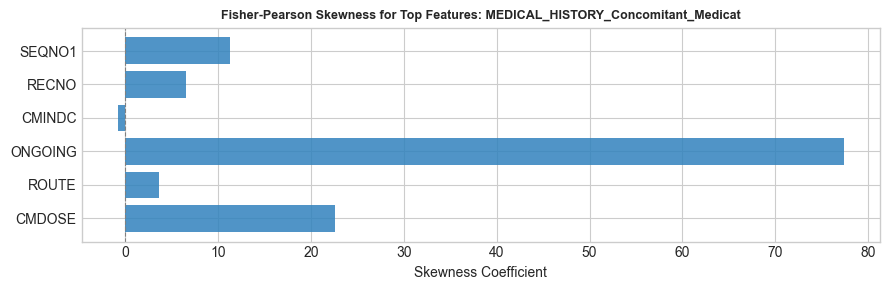

In [5]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "MEDICAL_HISTORY_Concomitant_Medication_Log_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: MEDICAL HISTORY/Concomitant_Medication_Log_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to MEDICAL_HISTORY_Concomitant_Medication_Log_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in MEDICAL_HISTORY_Concomitant_Medication_Log_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: MEDICAL_HISTORY_Concomitant_Medicat", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Deterministic Skip
- **Status**: `SKIPPED`
- **Deterministic Skip Reason**: `Insufficient usable numeric analytical features (0 < 2)`
- **Methodological Justification**: This dataset does not meet the scientific prerequisites for multivariate PCA (e.g. lacks $\ge 2$ continuous analytical measurements, is an unpivoted single-measurement log, represents cell repository inventory, or lacks adequate two-class participant coverage).

In [6]:
pca_res = unit_data.get("pca_results") or {}
skip_reason = pca_res.get("skip_reason") or unit_data.get("pca_skip_reason")
print(f"PCA Skip Reason: {skip_reason}")
print(f"Features Evaluated: {pca_res.get('feature_count', 0)} included, {pca_res.get('excluded_features_count', 0)} excluded")
if pca_res.get("excluded_features"):
    ex_df = pd.DataFrame(pca_res["excluded_features"][:10])
    print("\nExcluded Variables Sample:")
    display(ex_df)

PCA Skip Reason: Insufficient usable numeric analytical features (0 < 2)
Features Evaluated: 0 included, 23 excluded

Excluded Variables Sample:


,feature_name,reason
0,REC_ID,"Identifier, date, visit, demographic, instrume..."
1,PATNO,"Identifier, date, visit, demographic, instrume..."
2,EVENT_ID,"Identifier, date, visit, demographic, instrume..."
3,PAG_NAME,"Identifier, date, visit, demographic, instrume..."
4,CMTRT,Non-numeric / categorical string or free text
5,CMDOSE,Excessive missingness (50.5% > 40%)
6,CMDOSU,Non-numeric / categorical string or free text
7,CMDOSFRQ,Non-numeric / categorical string or free text
8,ROUTE,Excessive missingness (50.2% > 40%)
9,STARTDT,Non-numeric / categorical string or free text


---
## 2.3. Unit: `Medical_Conditions_Log_09Nov2026.csv` 
- **Unit Slug**: `MEDICAL_HISTORY_Medical_Conditions_Log_09Nov2026_csv`
- **Source Path**: `MEDICAL HISTORY/Medical_Conditions_Log_09Nov2026.csv`
- **Committed Unit Artifact**: [`MEDICAL_HISTORY_Medical_Conditions_Log_09Nov2026_csv.json`](../EDA/outputs/reports/units/MEDICAL_HISTORY_Medical_Conditions_Log_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, LOG_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Medical history and ongoing comorbidities coded by MedDRA body systems.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `SKIPPED`

UNIT ANALYSIS: MEDICAL HISTORY/Medical_Conditions_Log_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: SKIPPED
Dimensions: 10,486 analyzed rows x 15 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 40,101 (6,636 participants)
  - PD Retained:  8,806 rows (1,286 participants)
  - HC Retained:  1,680 rows (232 participants)
  - Non-Target Excluded: 18,399 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  11,216 rows

Exact Variable Schema & Storage Types (15 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"10,486",Identifier
1,PATNO,int64,0,0.0%,"1,518",Identifier
2,EVENT_ID,object,0,0.0%,1,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,76,Date / Timestamp / Visit
5,RESYR,float64,"8,134",77.6%,79,Analytical Numeric Measurement
6,MHDIAGYR,float64,34,0.3%,90,Diagnostic / Categorical Code
7,MHCAT,float64,0,0.0%,17,Diagnostic / Categorical Code
8,MHHX,float64,"1,197",11.4%,1,Analytical Numeric Measurement
9,MHDIAGDT,object,"1,193",11.4%,511,Date / Timestamp / Visit



Variable Role Distribution Summary:


,Count
variable_role,
Date / Timestamp / Visit,4
Identifier,3
Diagnostic / Categorical Code,3
Administrative Metadata,2
Analytical Numeric Measurement,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 19,119 / 157,290 (12.16%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (6 total, top 8):


,name,missing_count,missing_percent,variable_role
11,RESDT,"8,195",78.2%,Date / Timestamp / Visit
5,RESYR,"8,134",77.6%,Analytical Numeric Measurement
8,MHHX,"1,197",11.4%,Analytical Numeric Measurement
9,MHDIAGDT,"1,193",11.4%,Date / Timestamp / Visit
10,RESOLVD,366,3.5%,Diagnostic / Categorical Code
6,MHDIAGYR,34,0.3%,Diagnostic / Categorical Code



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"8,806"
1,HC,"1,680"



Numeric Summaries & Outlier Diagnostics (5 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,RESYR,2013.469,14.744,1940.0,2019.0,2026.0,-2.127,Strongly skewed (negative),211,65
1,MHDIAGYR,2011.951,177.659,1934.0,2015.0,20104.0,101.069,Strongly skewed (positive),753,1
2,MHCAT,110.018,5.642,102.0,111.0,141.0,1.974,Strongly skewed (positive),135,135
3,MHHX,1.000,0.000,1.0,1.0,1.0,0.000,Approximately symmetric,0,0
4,RESOLVD,0.246,0.430,0.0,0.0,1.0,1.183,Strongly skewed (positive),"2,485",0


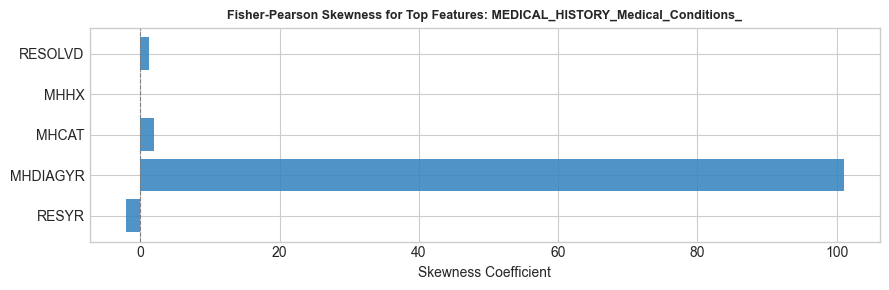

In [7]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "MEDICAL_HISTORY_Medical_Conditions_Log_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: MEDICAL HISTORY/Medical_Conditions_Log_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to MEDICAL_HISTORY_Medical_Conditions_Log_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in MEDICAL_HISTORY_Medical_Conditions_Log_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: MEDICAL_HISTORY_Medical_Conditions_", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Deterministic Skip
- **Status**: `SKIPPED`
- **Deterministic Skip Reason**: `Insufficient usable numeric analytical features (0 < 2)`
- **Methodological Justification**: This dataset does not meet the scientific prerequisites for multivariate PCA (e.g. lacks $\ge 2$ continuous analytical measurements, is an unpivoted single-measurement log, represents cell repository inventory, or lacks adequate two-class participant coverage).

In [8]:
pca_res = unit_data.get("pca_results") or {}
skip_reason = pca_res.get("skip_reason") or unit_data.get("pca_skip_reason")
print(f"PCA Skip Reason: {skip_reason}")
print(f"Features Evaluated: {pca_res.get('feature_count', 0)} included, {pca_res.get('excluded_features_count', 0)} excluded")
if pca_res.get("excluded_features"):
    ex_df = pd.DataFrame(pca_res["excluded_features"][:10])
    print("\nExcluded Variables Sample:")
    display(ex_df)

PCA Skip Reason: Insufficient usable numeric analytical features (0 < 2)
Features Evaluated: 0 included, 15 excluded

Excluded Variables Sample:


,feature_name,reason
0,REC_ID,"Identifier, date, visit, demographic, instrume..."
1,PATNO,"Identifier, date, visit, demographic, instrume..."
2,EVENT_ID,"Identifier, date, visit, demographic, instrume..."
3,PAG_NAME,"Identifier, date, visit, demographic, instrume..."
4,INFODT,"Identifier, date, visit, demographic, instrume..."
5,RESYR,"Identifier, date, visit, demographic, instrume..."
6,MHDIAGYR,"Identifier, date, visit, demographic, instrume..."
7,MHCAT,"Identifier, date, visit, demographic, instrume..."
8,MHHX,"Identifier, date, visit, demographic, instrume..."
9,MHDIAGDT,Non-numeric / categorical string or free text


---
## 2.4. Unit: `Vital_Signs_09Nov2026.csv` 
- **Unit Slug**: `MEDICAL_HISTORY_Vital_Signs_09Nov2026_csv`
- **Source Path**: `MEDICAL HISTORY/Vital_Signs_09Nov2026.csv`
- **Committed Unit Artifact**: [`MEDICAL_HISTORY_Vital_Signs_09Nov2026_csv.json`](../EDA/outputs/reports/units/MEDICAL_HISTORY_Vital_Signs_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Supine and standing blood pressures (orthostatic drop detection), pulse rate, weight, height, and temperature.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: MEDICAL HISTORY/Vital_Signs_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 18,592 analyzed rows x 18 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 33,495 (7,177 participants)
  - PD Retained:  14,589 rows (1,681 participants)
  - HC Retained:  4,003 rows (336 participants)
  - Non-Target Excluded: 12,501 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  2,402 rows

Exact Variable Schema & Storage Types (18 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"18,592",Identifier
1,PATNO,int64,0,0.0%,"2,017",Identifier
2,EVENT_ID,object,0,0.0%,29,Identifier
3,PAG_NAME,object,0,0.0%,2,Administrative Metadata
4,INFODT,object,0,0.0%,195,Date / Timestamp / Visit
5,WGTKG,float64,"8,372",45.0%,852,Analytical Numeric Measurement
6,HTCM,float64,"8,390",45.1%,73,Analytical Numeric Measurement
7,TEMPC,float64,127,0.7%,66,Analytical Numeric Measurement
8,BPARM,float64,46,0.2%,2,Analytical Numeric Measurement
9,SYSSUP,float64,41,0.2%,141,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,10
Identifier,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 17,439 / 334,656 (5.21%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (10 total, top 8):


,name,missing_count,missing_percent,variable_role
6,HTCM,"8,390",45.1%,Analytical Numeric Measurement
5,WGTKG,"8,372",45.0%,Analytical Numeric Measurement
14,HRSTND,128,0.7%,Analytical Numeric Measurement
7,TEMPC,127,0.7%,Analytical Numeric Measurement
12,SYSSTND,120,0.7%,Analytical Numeric Measurement
13,DIASTND,119,0.6%,Analytical Numeric Measurement
11,HRSUP,55,0.3%,Analytical Numeric Measurement
8,BPARM,46,0.2%,Analytical Numeric Measurement


... (2 outputs left out)

  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"14,589"
1,HC,"4,003"



Numeric Summaries & Outlier Diagnostics (10 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,WGTKG,78.421,16.925,0.0,77.4,200.0,0.594,Moderately skewed (positive),144,72
1,HTCM,171.279,10.426,0.0,172.0,213.0,-1.367,Strongly skewed (negative),23,23
2,TEMPC,36.494,1.823,0.0,36.5,206.0,57.287,Strongly skewed (positive),665,13
3,BPARM,1.470,0.499,1.0,1.0,2.0,0.121,Approximately symmetric,0,0
4,SYSSUP,130.916,17.593,0.0,130.0,232.0,0.515,Moderately skewed (positive),340,120
5,DIASUP,77.544,10.420,0.0,78.0,131.0,0.113,Approximately symmetric,207,113
6,HRSUP,68.046,11.200,0.0,67.0,138.0,0.510,Moderately skewed (positive),245,113
7,SYSSTND,127.193,18.102,0.0,126.0,223.0,0.352,Approximately symmetric,301,102
8,DIASTND,79.351,11.137,0.0,80.0,133.0,0.070,Approximately symmetric,288,108
9,HRSTND,74.869,12.280,0.0,74.0,188.0,0.498,Approximately symmetric,232,105


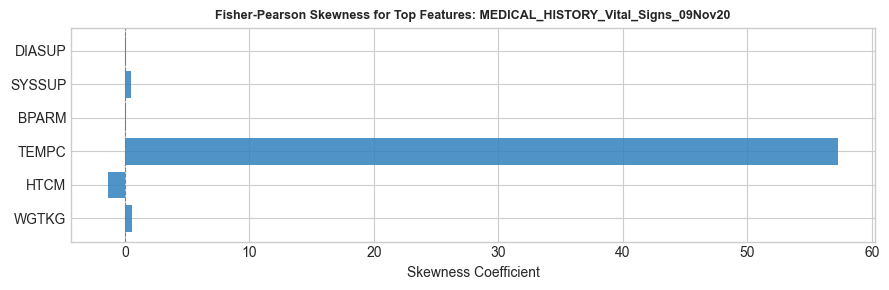

In [9]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "MEDICAL_HISTORY_Vital_Signs_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: MEDICAL HISTORY/Vital_Signs_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to MEDICAL_HISTORY_Vital_Signs_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in MEDICAL_HISTORY_Vital_Signs_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: MEDICAL_HISTORY_Vital_Signs_09Nov20", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `7` continuous analytical measurements
- **Excluded Features**: `11` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `40.9%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,681 participants
  - Initial Eligible HC: 336 participants
  - Class-Balanced Fit Size: 336 participants per class (Total Fit N=672)
  - Total Projected Participants: 2,017


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,40.86%,40.86%
1,PC2,24.81%,65.67%
2,PC3,14.24%,79.91%
3,PC4,9.31%,89.21%
4,PC5,5.61%,94.83%



Top PC1 Feature Loadings:


,feature_name,loading
0,DIASUP,0.4998
1,SYSSUP,0.4984
2,DIASTND,0.4913
3,SYSSTND,0.4834
4,HRSUP,0.1423


Scree & Eigenvector Loadings Plot:


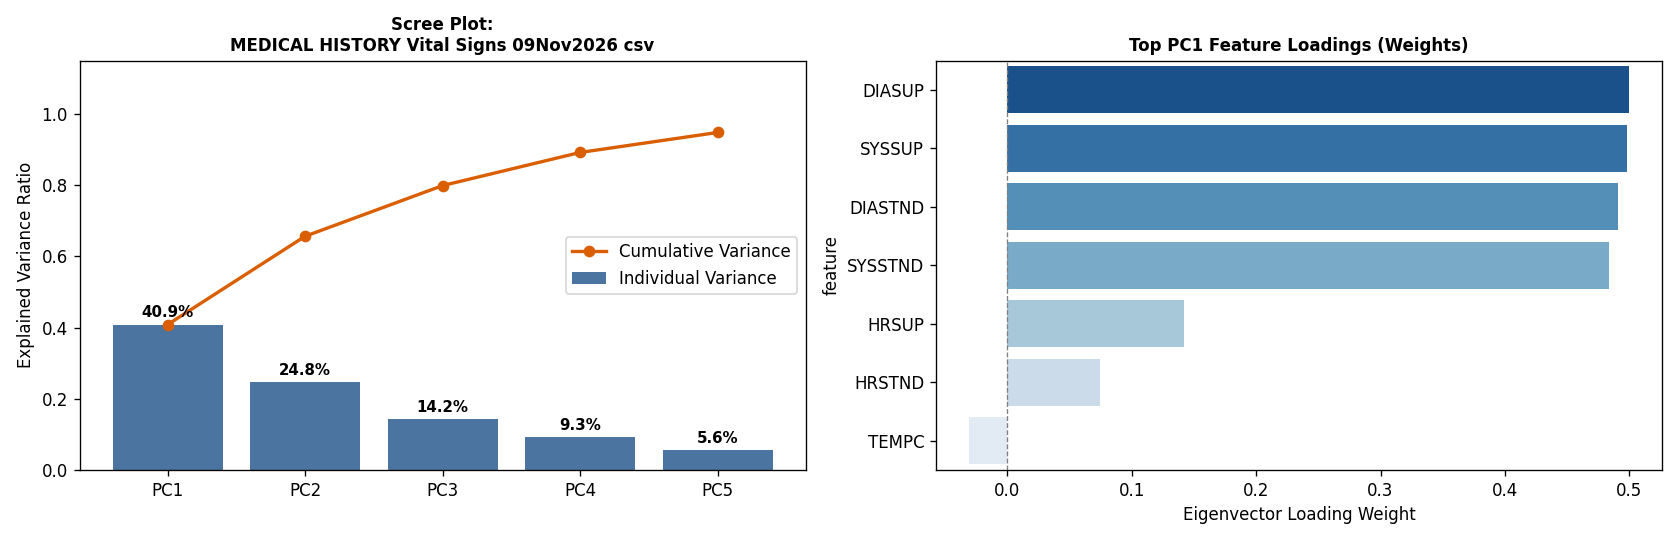

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


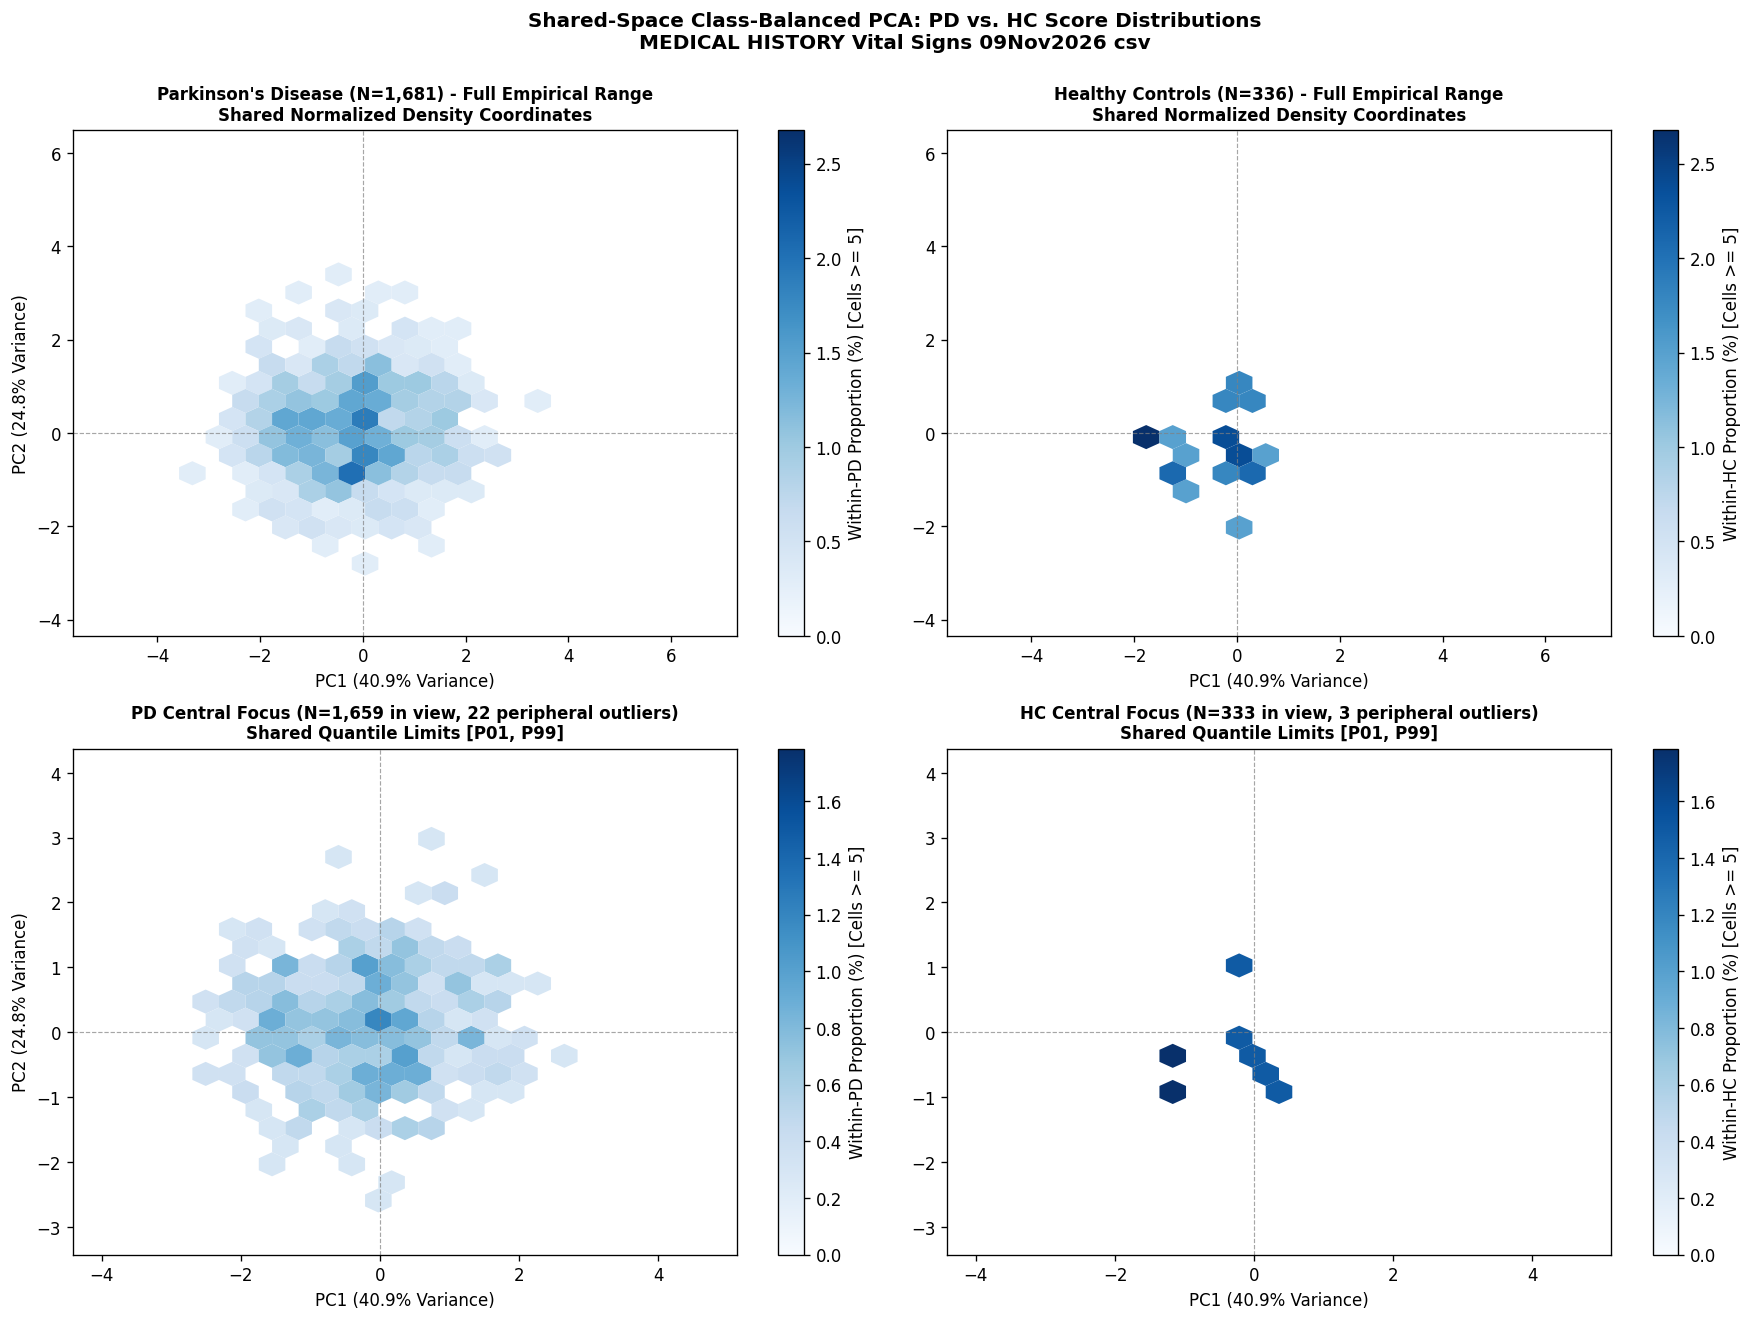

In [10]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/MEDICAL_HISTORY_Vital_Signs_09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/MEDICAL_HISTORY_Vital_Signs_09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 2.5. Unit: `Primary_Research_Diagnosis_09Nov2026.csv` 
- **Unit Slug**: `MEDICAL_HISTORY_Primary_Research_Diagnosis_09Nov2026_csv`
- **Source Path**: `MEDICAL HISTORY/Primary_Research_Diagnosis_09Nov2026.csv`
- **Committed Unit Artifact**: [`MEDICAL_HISTORY_Primary_Research_Diagnosis_09Nov2026_csv.json`](../EDA/outputs/reports/units/MEDICAL_HISTORY_Primary_Research_Diagnosis_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Clinician diagnostic certainty and classification across visits (Idiopathic PD, Multiple System Atrophy, Progressive Supranuclear Palsy, Essential Tremor).`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `SKIPPED`

UNIT ANALYSIS: MEDICAL HISTORY/Primary_Research_Diagnosis_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: SKIPPED
Dimensions: 15,350 analyzed rows x 19 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 30,813 (5,579 participants)
  - PD Retained:  12,479 rows (1,680 participants)
  - HC Retained:  2,871 rows (336 participants)
  - Non-Target Excluded: 14,873 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  590 rows

Exact Variable Schema & Storage Types (19 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"15,350",Identifier
1,PATNO,int64,0,0.0%,"2,016",Identifier
2,EVENT_ID,object,0,0.0%,41,Identifier
3,PAG_NAME,object,0,0.0%,3,Administrative Metadata
4,INFODT,object,"1,816",11.8%,195,Date / Timestamp / Visit
5,PRIMDIAG,int64,0,0.0%,13,Diagnostic / Categorical Code
6,NEWDIAGEXP,object,"15,098",98.4%,206,Demographic / Covariate
7,OTHNEURO,object,"15,177",98.9%,118,Diagnostic / Categorical Code
8,DXLVL,float64,"5,982",39.0%,4,Diagnostic / Categorical Code
9,BIORV,float64,"14,633",95.3%,2,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,7
Diagnostic / Categorical Code,3
Identifier,3
Date / Timestamp / Visit,2
Administrative Metadata,2
Demographic / Covariate,1
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 141,151 / 291,650 (48.40%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (11 total, top 8):


,name,missing_count,missing_percent,variable_role
15,KBIAFCT,"15,280",99.5%,Analytical Numeric Measurement
7,OTHNEURO,"15,177",98.9%,Diagnostic / Categorical Code
6,NEWDIAGEXP,"15,098",98.4%,Demographic / Covariate
13,UPDRS3,"14,633",95.3%,Analytical Numeric Measurement
9,BIORV,"14,633",95.3%,Analytical Numeric Measurement
11,DATSCAN,"14,633",95.3%,Analytical Numeric Measurement
10,ASYNSAA,"14,633",95.3%,Analytical Numeric Measurement
14,OTHBIO,"14,633",95.3%,Analytical Numeric Measurement


... (2 outputs left out)

  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"12,479"
1,HC,"2,871"



Numeric Summaries & Outlier Diagnostics (9 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,PRIMDIAG,4.918,11.149,1.0,1.0,97.0,5.859,Strongly skewed (positive),"3,060",154
1,DXLVL,1.066,0.296,1.0,1.0,4.0,5.355,Strongly skewed (positive),513,513
2,BIORV,0.098,0.297,0.0,0.0,1.0,2.717,Strongly skewed (positive),70,70
3,ASYNSAA,0.039,0.194,0.0,0.0,1.0,4.769,Strongly skewed (positive),28,28
4,DATSCAN,0.050,0.219,0.0,0.0,1.0,4.128,Strongly skewed (positive),36,36
5,UPSIT,0.020,0.138,0.0,0.0,1.0,6.960,Strongly skewed (positive),14,14
6,UPDRS3,0.061,0.240,0.0,0.0,1.0,3.663,Strongly skewed (positive),44,44
7,OTHBIO,0.008,0.091,0.0,0.0,1.0,10.817,Strongly skewed (positive),6,6
8,KBIAFCT,0.386,0.490,0.0,0.0,1.0,0.480,Approximately symmetric,0,0


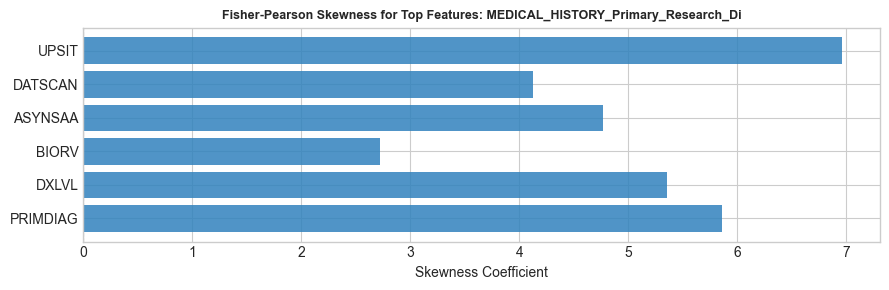

In [11]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "MEDICAL_HISTORY_Primary_Research_Diagnosis_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: MEDICAL HISTORY/Primary_Research_Diagnosis_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to MEDICAL_HISTORY_Primary_Research_Diagnosis_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in MEDICAL_HISTORY_Primary_Research_Diagnosis_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: MEDICAL_HISTORY_Primary_Research_Di", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Deterministic Skip
- **Status**: `SKIPPED`
- **Deterministic Skip Reason**: `Insufficient usable numeric analytical features (0 < 2)`
- **Methodological Justification**: This dataset does not meet the scientific prerequisites for multivariate PCA (e.g. lacks $\ge 2$ continuous analytical measurements, is an unpivoted single-measurement log, represents cell repository inventory, or lacks adequate two-class participant coverage).

In [12]:
pca_res = unit_data.get("pca_results") or {}
skip_reason = pca_res.get("skip_reason") or unit_data.get("pca_skip_reason")
print(f"PCA Skip Reason: {skip_reason}")
print(f"Features Evaluated: {pca_res.get('feature_count', 0)} included, {pca_res.get('excluded_features_count', 0)} excluded")
if pca_res.get("excluded_features"):
    ex_df = pd.DataFrame(pca_res["excluded_features"][:10])
    print("\nExcluded Variables Sample:")
    display(ex_df)

PCA Skip Reason: Insufficient usable numeric analytical features (0 < 2)
Features Evaluated: 0 included, 19 excluded

Excluded Variables Sample:


,feature_name,reason
0,REC_ID,"Identifier, date, visit, demographic, instrume..."
1,PATNO,"Identifier, date, visit, demographic, instrume..."
2,EVENT_ID,"Identifier, date, visit, demographic, instrume..."
3,PAG_NAME,"Identifier, date, visit, demographic, instrume..."
4,INFODT,"Identifier, date, visit, demographic, instrume..."
5,PRIMDIAG,"Identifier, date, visit, demographic, instrume..."
6,NEWDIAGEXP,"Identifier, date, visit, demographic, instrume..."
7,OTHNEURO,"Identifier, date, visit, demographic, instrume..."
8,DXLVL,"Identifier, date, visit, demographic, instrume..."
9,BIORV,"Identifier, date, visit, demographic, instrume..."


---
## 2.6. Unit: `Clinical_Diagnosis_09Nov2026.csv` 
- **Unit Slug**: `MEDICAL_HISTORY_Clinical_Diagnosis_09Nov2026_csv`
- **Source Path**: `MEDICAL HISTORY/Clinical_Diagnosis_09Nov2026.csv`
- **Committed Unit Artifact**: [`MEDICAL_HISTORY_Clinical_Diagnosis_09Nov2026_csv.json`](../EDA/outputs/reports/units/MEDICAL_HISTORY_Clinical_Diagnosis_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Site-investigator diagnostic logs verifying inclusion/exclusion criteria fulfillment.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `SKIPPED`

UNIT ANALYSIS: MEDICAL HISTORY/Clinical_Diagnosis_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: SKIPPED
Dimensions: 7,170 analyzed rows x 12 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 19,752 (4,611 participants)
  - PD Retained:  5,960 rows (1,299 participants)
  - HC Retained:  1,210 rows (231 participants)
  - Non-Target Excluded: 12,268 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  314 rows

Exact Variable Schema & Storage Types (12 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"7,170",Identifier
1,PATNO,int64,0,0.0%,"1,530",Identifier
2,EVENT_ID,object,0,0.0%,33,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,46,Date / Timestamp / Visit
5,NEWDIAG,int64,0,0.0%,10,Diagnostic / Categorical Code
6,NEWDIAGOTHER,object,"7,109",99.2%,42,Diagnostic / Categorical Code
7,DIAGSINLV,float64,567,7.9%,2,Diagnostic / Categorical Code
8,DIAGDT,object,"7,119",99.3%,31,Date / Timestamp / Visit
9,ORIG_ENTRY,object,0,0.0%,45,Administrative Metadata



Variable Role Distribution Summary:


,Count
variable_role,
Identifier,3
Date / Timestamp / Visit,3
Diagnostic / Categorical Code,3
Administrative Metadata,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 14,795 / 86,040 (17.20%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (3 total, top 8):


,name,missing_count,missing_percent,variable_role
8,DIAGDT,"7,119",99.3%,Date / Timestamp / Visit
6,NEWDIAGOTHER,"7,109",99.2%,Diagnostic / Categorical Code
7,DIAGSINLV,567,7.9%,Diagnostic / Categorical Code



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"5,960"
1,HC,"1,210"



Numeric Summaries & Outlier Diagnostics (2 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,NEWDIAG,4.552,10.465,1.0,1.0,97.0,6.131,Strongly skewed (positive),"1,322",61
1,DIAGSINLV,0.008,0.088,0.0,0.0,1.0,11.249,Strongly skewed (positive),51,51


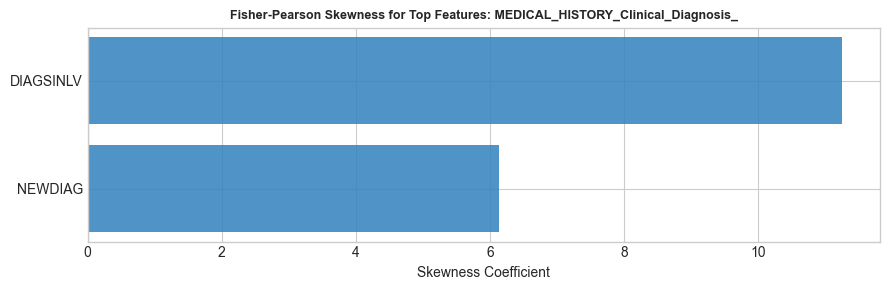

In [13]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "MEDICAL_HISTORY_Clinical_Diagnosis_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: MEDICAL HISTORY/Clinical_Diagnosis_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to MEDICAL_HISTORY_Clinical_Diagnosis_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in MEDICAL_HISTORY_Clinical_Diagnosis_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: MEDICAL_HISTORY_Clinical_Diagnosis_", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Deterministic Skip
- **Status**: `SKIPPED`
- **Deterministic Skip Reason**: `Insufficient usable numeric analytical features (0 < 2)`
- **Methodological Justification**: This dataset does not meet the scientific prerequisites for multivariate PCA (e.g. lacks $\ge 2$ continuous analytical measurements, is an unpivoted single-measurement log, represents cell repository inventory, or lacks adequate two-class participant coverage).

In [14]:
pca_res = unit_data.get("pca_results") or {}
skip_reason = pca_res.get("skip_reason") or unit_data.get("pca_skip_reason")
print(f"PCA Skip Reason: {skip_reason}")
print(f"Features Evaluated: {pca_res.get('feature_count', 0)} included, {pca_res.get('excluded_features_count', 0)} excluded")
if pca_res.get("excluded_features"):
    ex_df = pd.DataFrame(pca_res["excluded_features"][:10])
    print("\nExcluded Variables Sample:")
    display(ex_df)

PCA Skip Reason: Insufficient usable numeric analytical features (0 < 2)
Features Evaluated: 0 included, 12 excluded

Excluded Variables Sample:


,feature_name,reason
0,REC_ID,"Identifier, date, visit, demographic, instrume..."
1,PATNO,"Identifier, date, visit, demographic, instrume..."
2,EVENT_ID,"Identifier, date, visit, demographic, instrume..."
3,PAG_NAME,"Identifier, date, visit, demographic, instrume..."
4,INFODT,"Identifier, date, visit, demographic, instrume..."
5,NEWDIAG,"Identifier, date, visit, demographic, instrume..."
6,NEWDIAGOTHER,"Identifier, date, visit, demographic, instrume..."
7,DIAGSINLV,"Identifier, date, visit, demographic, instrume..."
8,DIAGDT,Non-numeric / categorical string or free text
9,ORIG_ENTRY,"Identifier, date, visit, demographic, instrume..."


---
## 2.7. Unit: `Determination_of_Freezing_and_Falls_09Nov2026.csv` 
- **Unit Slug**: `MEDICAL_HISTORY_Determination_of_Freezing_and_Falls_09Nov2026_csv`
- **Source Path**: `MEDICAL HISTORY/Determination_of_Freezing_and_Falls_09Nov2026.csv`
- **Committed Unit Artifact**: [`MEDICAL_HISTORY_Determination_of_Freezing_and_Falls_09Nov2026_csv.json`](../EDA/outputs/reports/units/MEDICAL_HISTORY_Determination_of_Freezing_and_Falls_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Longitudinal tracking of Freezing of Gait (FOG) questionnaire responses and fall frequencies.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: MEDICAL HISTORY/Determination_of_Freezing_and_Falls_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 6,250 analyzed rows x 26 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID'], ['PATNO', 'INFODT']]

Target Cohort Filtering Denominators:
  - Initial Rows: 14,864 (4,830 participants)
  - PD Retained:  5,120 rows (1,436 participants)
  - HC Retained:  1,130 rows (256 participants)
  - Non-Target Excluded: 8,291 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  323 rows

Exact Variable Schema & Storage Types (26 columns):
Showing first 20 of 26 columns (complete schema committed to MEDICAL_HISTORY_Determination_of_Freezing_and_Falls_09Nov2026_csv.json):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"6,250",Identifier
1,PATNO,int64,0,0.0%,"1,692",Identifier
2,EVENT_ID,object,0,0.0%,18,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,92,Date / Timestamp / Visit
5,PTCGBOTH,int64,0,0.0%,3,Analytical Numeric Measurement
6,FRZGT1W,float64,2,0.0%,5,Analytical Numeric Measurement
7,FLNFR1W,float64,2,0.0%,5,Analytical Numeric Measurement
8,FRZGT12M,float64,1,0.0%,5,Analytical Numeric Measurement
9,FLNFR12M,float64,2,0.0%,5,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,18
Identifier,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 57,335 / 162,500 (35.28%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (17 total, top 8):


,name,missing_count,missing_percent,variable_role
14,HINJNOLC,"4,411",70.6%,Analytical Numeric Measurement
16,INJSTCH,"4,411",70.6%,Analytical Numeric Measurement
17,INJOTH,"4,411",70.6%,Analytical Numeric Measurement
15,HINJLOC2,"4,411",70.6%,Analytical Numeric Measurement
11,INJFRUE,"4,410",70.6%,Analytical Numeric Measurement
12,INJFRSKL,"4,410",70.6%,Analytical Numeric Measurement
13,INJFROTH,"4,410",70.6%,Analytical Numeric Measurement
19,FLLERVIS,"4,409",70.5%,Analytical Numeric Measurement



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"5,120"
1,HC,"1,130"



Numeric Summaries & Outlier Diagnostics (18 continuous/discrete features):
Showing top 10 of 18 features (full distribution profiles in MEDICAL_HISTORY_Determination_of_Freezing_and_Falls_09Nov2026_csv.json):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,PTCGBOTH,1.180,0.568,1.0,1.0,3.0,2.871,Strongly skewed (positive),573,549
1,FRZGT1W,0.347,0.796,0.0,0.0,4.0,2.375,Strongly skewed (positive),"1,214",246
2,FLNFR1W,0.252,0.580,0.0,0.0,4.0,2.661,Strongly skewed (positive),"1,194",322
3,FRZGT12M,0.355,0.804,0.0,0.0,4.0,2.347,Strongly skewed (positive),"1,238",252
4,FLNFR12M,0.333,0.617,0.0,0.0,4.0,2.037,Strongly skewed (positive),45,45
5,INJFRHIP,0.032,0.176,0.0,0.0,1.0,5.318,Strongly skewed (positive),59,59
6,INJFRUE,0.048,0.213,0.0,0.0,1.0,4.241,Strongly skewed (positive),88,88
7,INJFRSKL,0.005,0.074,0.0,0.0,1.0,13.465,Strongly skewed (positive),10,10
8,INJFROTH,0.045,0.208,0.0,0.0,1.0,4.387,Strongly skewed (positive),83,83
9,HINJNOLC,0.101,0.301,0.0,0.0,1.0,2.658,Strongly skewed (positive),185,0


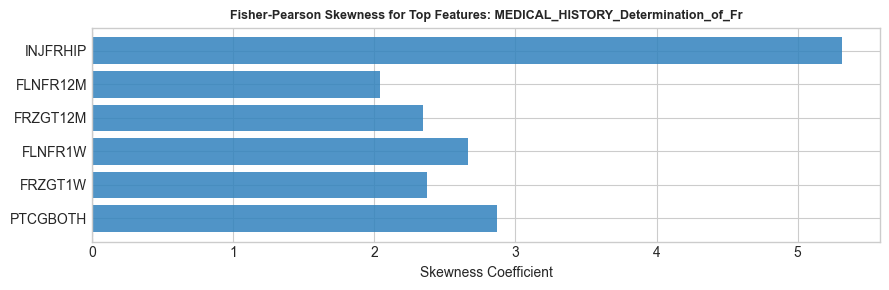

In [15]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "MEDICAL_HISTORY_Determination_of_Freezing_and_Falls_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: MEDICAL HISTORY/Determination_of_Freezing_and_Falls_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to MEDICAL_HISTORY_Determination_of_Freezing_and_Falls_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in MEDICAL_HISTORY_Determination_of_Freezing_and_Falls_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: MEDICAL_HISTORY_Determination_of_Fr", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `4` continuous analytical measurements
- **Excluded Features**: `22` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `65.1%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,436 participants
  - Initial Eligible HC: 256 participants
  - Class-Balanced Fit Size: 256 participants per class (Total Fit N=512)
  - Total Projected Participants: 1,692


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,65.14%,65.14%
1,PC2,25.32%,90.46%
2,PC3,7.97%,98.44%
3,PC4,1.56%,100.00%



Top PC1 Feature Loadings:


,feature_name,loading
0,FRZGT12M,0.5459
1,FRZGT1W,0.5288
2,FLNFR1W,0.4632
3,FLNFR12M,0.4558


Scree & Eigenvector Loadings Plot:


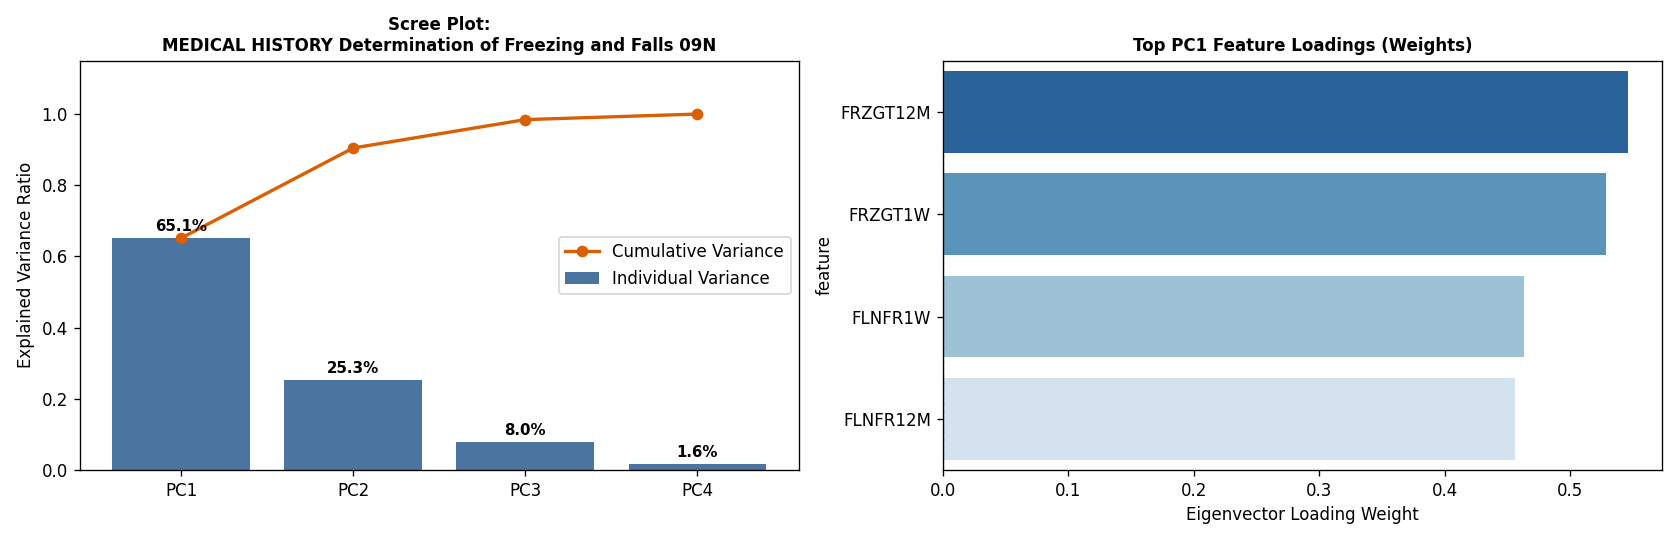

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


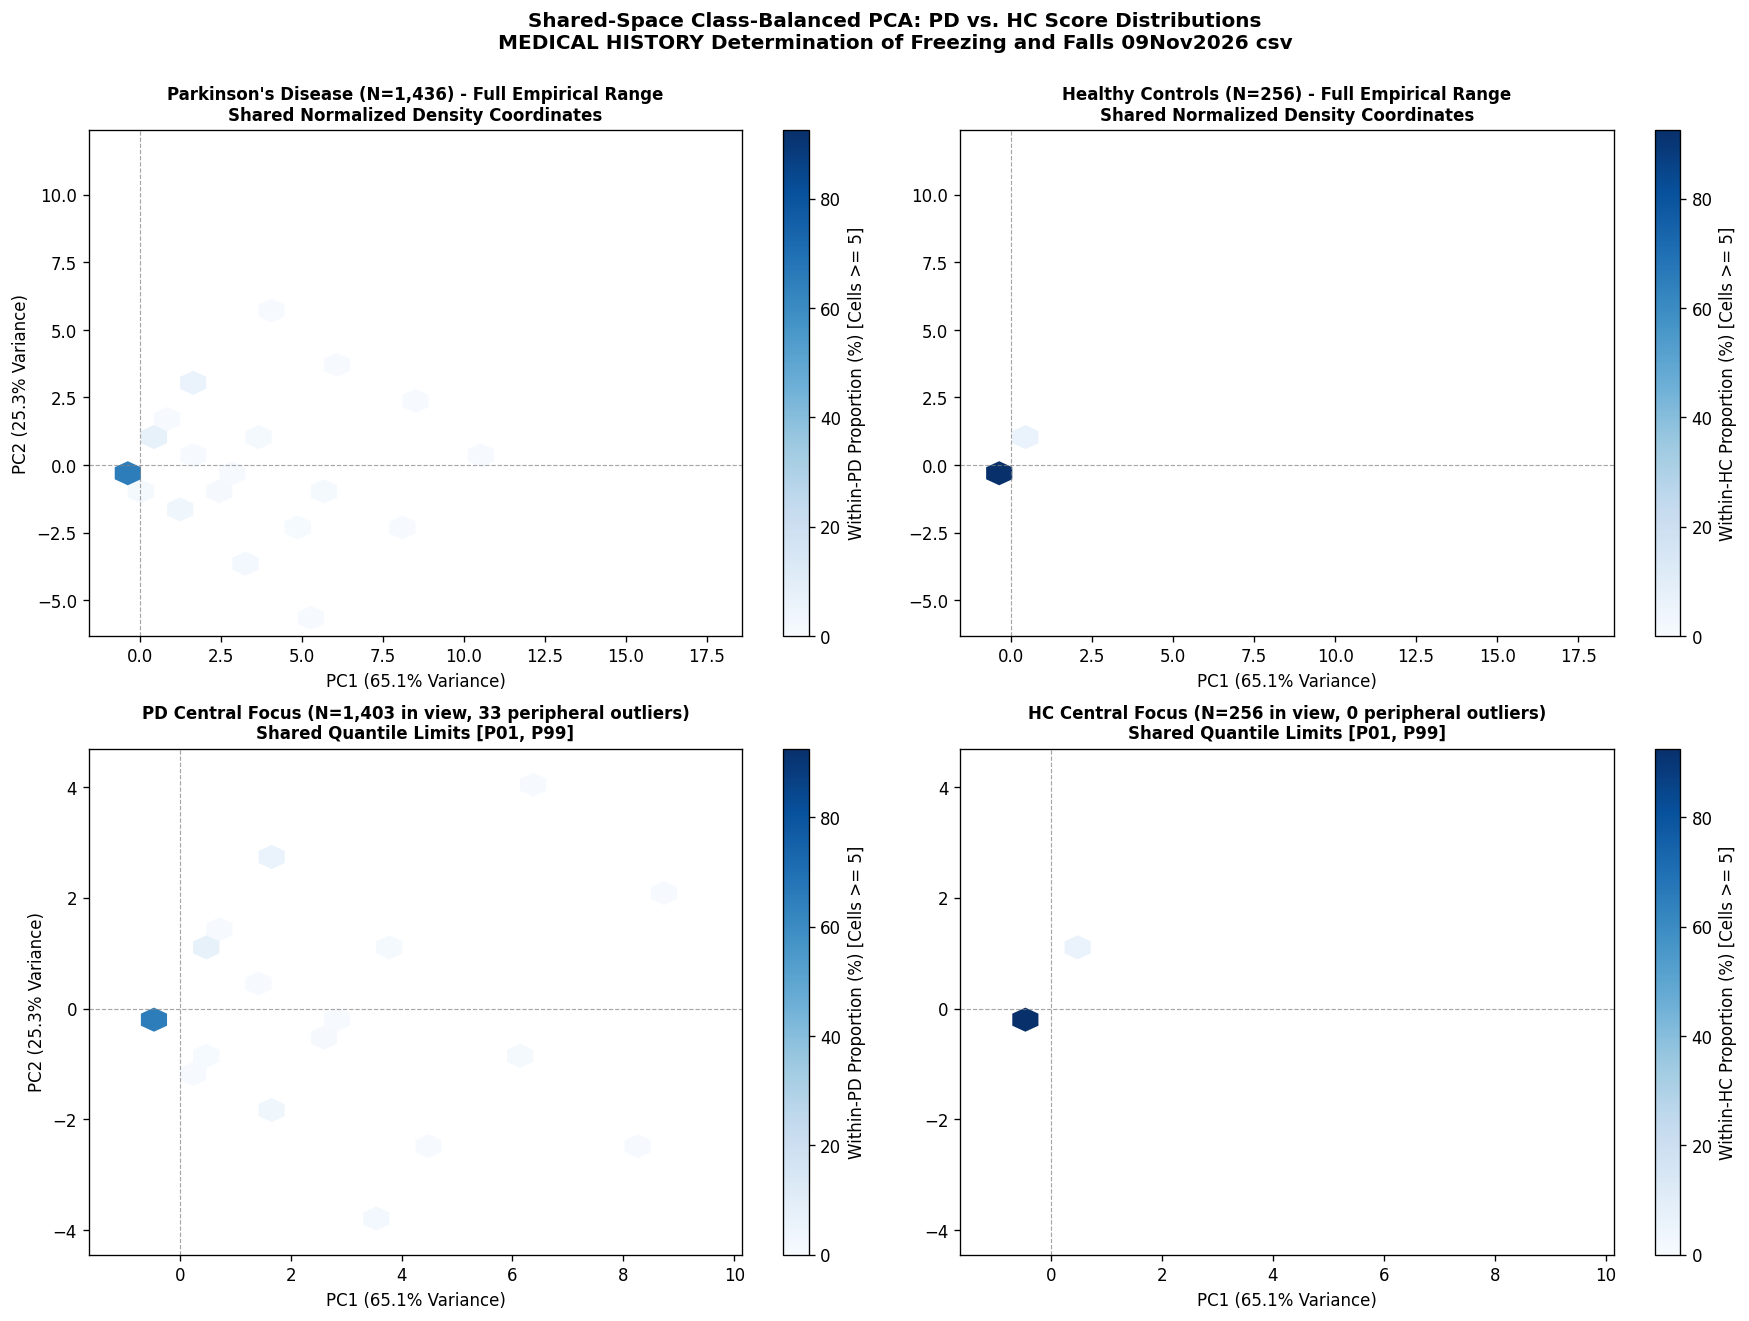

In [16]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/MEDICAL_HISTORY_Determination_of_Freezing_and_Falls_09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/MEDICAL_HISTORY_Determination_of_Freezing_and_Falls_09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 2.8. Unit: `General_Physical_Exam_09Nov2026.csv` 
- **Unit Slug**: `MEDICAL_HISTORY_General_Physical_Exam_09Nov2026_csv`
- **Source Path**: `MEDICAL HISTORY/General_Physical_Exam_09Nov2026.csv`
- **Committed Unit Artifact**: [`MEDICAL_HISTORY_General_Physical_Exam_09Nov2026_csv.json`](../EDA/outputs/reports/units/MEDICAL_HISTORY_General_Physical_Exam_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID, EXAM_ITEM)`
- **Selection Tier**: `Supporting` | **Role**: `Itemized physical examination findings across organ systems.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `SKIPPED`

UNIT ANALYSIS: MEDICAL HISTORY/General_Physical_Exam_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: SKIPPED
Dimensions: 22,167 analyzed rows x 11 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 79,708 (7,236 participants)
  - PD Retained:  18,480 rows (1,677 participants)
  - HC Retained:  3,687 rows (335 participants)
  - Non-Target Excluded: 32,967 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  24,574 rows

Exact Variable Schema & Storage Types (11 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"22,167",Identifier
1,PATNO,int64,0,0.0%,"2,012",Identifier
2,EVENT_ID,object,0,0.0%,3,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,177,Date / Timestamp / Visit
5,PESEQ,int64,0,0.0%,12,Administrative Metadata
6,PECAT,object,0,0.0%,12,Administrative Metadata
7,ABNORM,float64,55,0.2%,3,Analytical Numeric Measurement
8,ORIG_ENTRY,object,0,0.0%,172,Administrative Metadata
9,LAST_UPDATE,object,0,0.0%,"1,620",Date / Timestamp / Visit



Variable Role Distribution Summary:


,Count
variable_role,
Administrative Metadata,4
Identifier,3
Date / Timestamp / Visit,2
Analytical Numeric Measurement,1
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 55 / 243,837 (0.02%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (1 total, top 8):


,name,missing_count,missing_percent,variable_role
7,ABNORM,55,0.2%,Analytical Numeric Measurement


... (2 outputs left out)

  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"18,480"
1,HC,"3,687"



Numeric Summaries & Outlier Diagnostics (2 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,PESEQ,6.00,3.163,1.0,6.0,12.0,0.000,Approximately symmetric,0,0
1,ABNORM,0.09,0.331,0.0,0.0,2.0,3.948,Strongly skewed (positive),"1,676",308


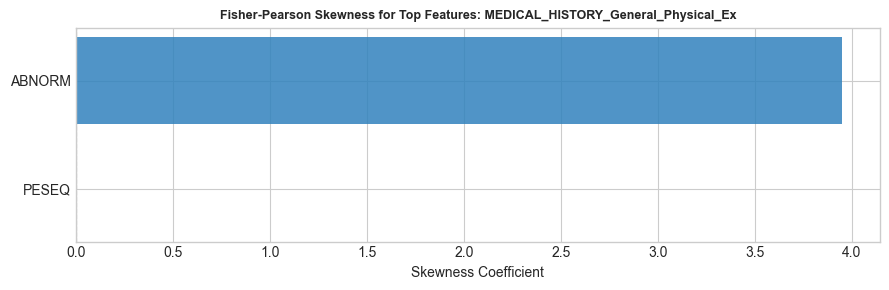

In [17]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "MEDICAL_HISTORY_General_Physical_Exam_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: MEDICAL HISTORY/General_Physical_Exam_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to MEDICAL_HISTORY_General_Physical_Exam_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in MEDICAL_HISTORY_General_Physical_Exam_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: MEDICAL_HISTORY_General_Physical_Ex", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Deterministic Skip
- **Status**: `SKIPPED`
- **Deterministic Skip Reason**: `Insufficient usable numeric analytical features (0 < 2)`
- **Methodological Justification**: This dataset does not meet the scientific prerequisites for multivariate PCA (e.g. lacks $\ge 2$ continuous analytical measurements, is an unpivoted single-measurement log, represents cell repository inventory, or lacks adequate two-class participant coverage).

In [18]:
pca_res = unit_data.get("pca_results") or {}
skip_reason = pca_res.get("skip_reason") or unit_data.get("pca_skip_reason")
print(f"PCA Skip Reason: {skip_reason}")
print(f"Features Evaluated: {pca_res.get('feature_count', 0)} included, {pca_res.get('excluded_features_count', 0)} excluded")
if pca_res.get("excluded_features"):
    ex_df = pd.DataFrame(pca_res["excluded_features"][:10])
    print("\nExcluded Variables Sample:")
    display(ex_df)

PCA Skip Reason: Insufficient usable numeric analytical features (0 < 2)
Features Evaluated: 0 included, 11 excluded

Excluded Variables Sample:


,feature_name,reason
0,REC_ID,"Identifier, date, visit, demographic, instrume..."
1,PATNO,"Identifier, date, visit, demographic, instrume..."
2,EVENT_ID,"Identifier, date, visit, demographic, instrume..."
3,PAG_NAME,"Identifier, date, visit, demographic, instrume..."
4,INFODT,"Identifier, date, visit, demographic, instrume..."
5,PESEQ,"Identifier, date, visit, demographic, instrume..."
6,PECAT,"Identifier, date, visit, demographic, instrume..."
7,ABNORM,"Identifier, date, visit, demographic, instrume..."
8,ORIG_ENTRY,"Identifier, date, visit, demographic, instrume..."
9,LAST_UPDATE,"Identifier, date, visit, demographic, instrume..."


---
## 2.9. Unit: `Neurological_Exam_09Nov2026.csv` 
- **Unit Slug**: `MEDICAL_HISTORY_Neurological_Exam_09Nov2026_csv`
- **Source Path**: `MEDICAL HISTORY/Neurological_Exam_09Nov2026.csv`
- **Committed Unit Artifact**: [`MEDICAL_HISTORY_Neurological_Exam_09Nov2026_csv.json`](../EDA/outputs/reports/units/MEDICAL_HISTORY_Neurological_Exam_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Cranial nerves, deep tendon reflexes, and sensory exam logs.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: MEDICAL HISTORY/Neurological_Exam_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 10,403 analyzed rows x 17 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 22,643 (7,253 participants)
  - PD Retained:  8,296 rows (1,683 participants)
  - HC Retained:  2,107 rows (335 participants)
  - Non-Target Excluded: 9,990 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  2,250 rows

Exact Variable Schema & Storage Types (17 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"10,403",Identifier
1,PATNO,int64,0,0.0%,"2,018",Identifier
2,EVENT_ID,object,0,0.0%,24,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,195,Date / Timestamp / Visit
5,MTRRSP,float64,0,0.0%,4,Analytical Numeric Measurement
6,CORDRSP,float64,1,0.0%,4,Analytical Numeric Measurement
7,SENRSP,int64,0,0.0%,4,Analytical Numeric Measurement
8,RFLXRSP,float64,0,0.0%,4,Analytical Numeric Measurement
9,PLRRRSP,float64,"5,680",54.6%,5,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,9
Identifier,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 20,807 / 176,851 (11.77%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (5 total, top 8):


,name,missing_count,missing_percent,variable_role
9,PLRRRSP,"5,680",54.6%,Analytical Numeric Measurement
10,PLRLRSP,"5,680",54.6%,Analytical Numeric Measurement
11,GAITRSP,"4,723",45.4%,Analytical Numeric Measurement
12,MNTLRSP,"4,723",45.4%,Analytical Numeric Measurement
6,CORDRSP,1,0.0%,Analytical Numeric Measurement



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"8,296"
1,HC,"2,107"



Numeric Summaries & Outlier Diagnostics (9 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,MTRRSP,0.080,0.369,0.0,0.0,3.0,5.841,Strongly skewed (positive),609,121
1,CORDRSP,0.051,0.281,0.0,0.0,3.0,7.165,Strongly skewed (positive),412,412
2,SENRSP,0.156,0.478,0.0,0.0,3.0,3.863,Strongly skewed (positive),"1,268",205
3,RFLXRSP,0.302,0.565,0.0,0.0,3.0,2.238,Strongly skewed (positive),161,240
4,PLRRRSP,0.307,0.758,0.0,0.0,4.0,2.241,Strongly skewed (positive),698,93
5,PLRLRSP,0.302,0.752,0.0,0.0,4.0,2.278,Strongly skewed (positive),691,93
6,GAITRSP,0.109,0.396,0.0,0.0,3.0,4.696,Strongly skewed (positive),502,64
7,MNTLRSP,0.033,0.207,0.0,0.0,3.0,7.952,Strongly skewed (positive),162,162
8,CNRSP,0.438,0.742,0.0,0.0,3.0,1.452,Strongly skewed (positive),85,85


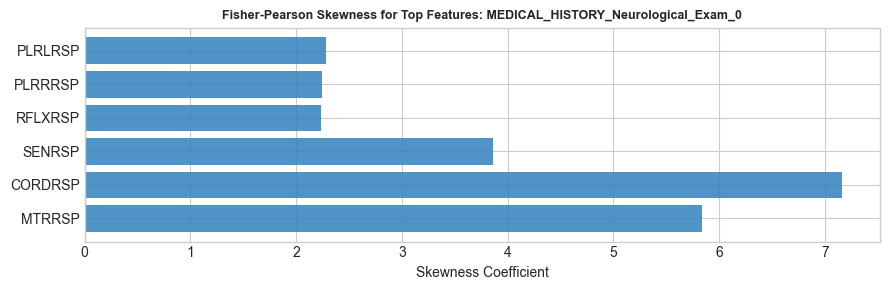

In [19]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "MEDICAL_HISTORY_Neurological_Exam_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: MEDICAL HISTORY/Neurological_Exam_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to MEDICAL_HISTORY_Neurological_Exam_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in MEDICAL_HISTORY_Neurological_Exam_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: MEDICAL_HISTORY_Neurological_Exam_0", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `5` continuous analytical measurements
- **Excluded Features**: `12` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `32.5%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,683 participants
  - Initial Eligible HC: 335 participants
  - Class-Balanced Fit Size: 335 participants per class (Total Fit N=670)
  - Total Projected Participants: 2,018


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,32.49%,32.49%
1,PC2,20.59%,53.07%
2,PC3,19.26%,72.34%
3,PC4,15.43%,87.77%
4,PC5,12.23%,100.00%



Top PC1 Feature Loadings:


,feature_name,loading
0,SENRSP,0.5507
1,MTRRSP,0.4873
2,CORDRSP,0.4475
3,RFLXRSP,0.3696
4,CNRSP,0.3499


Scree & Eigenvector Loadings Plot:


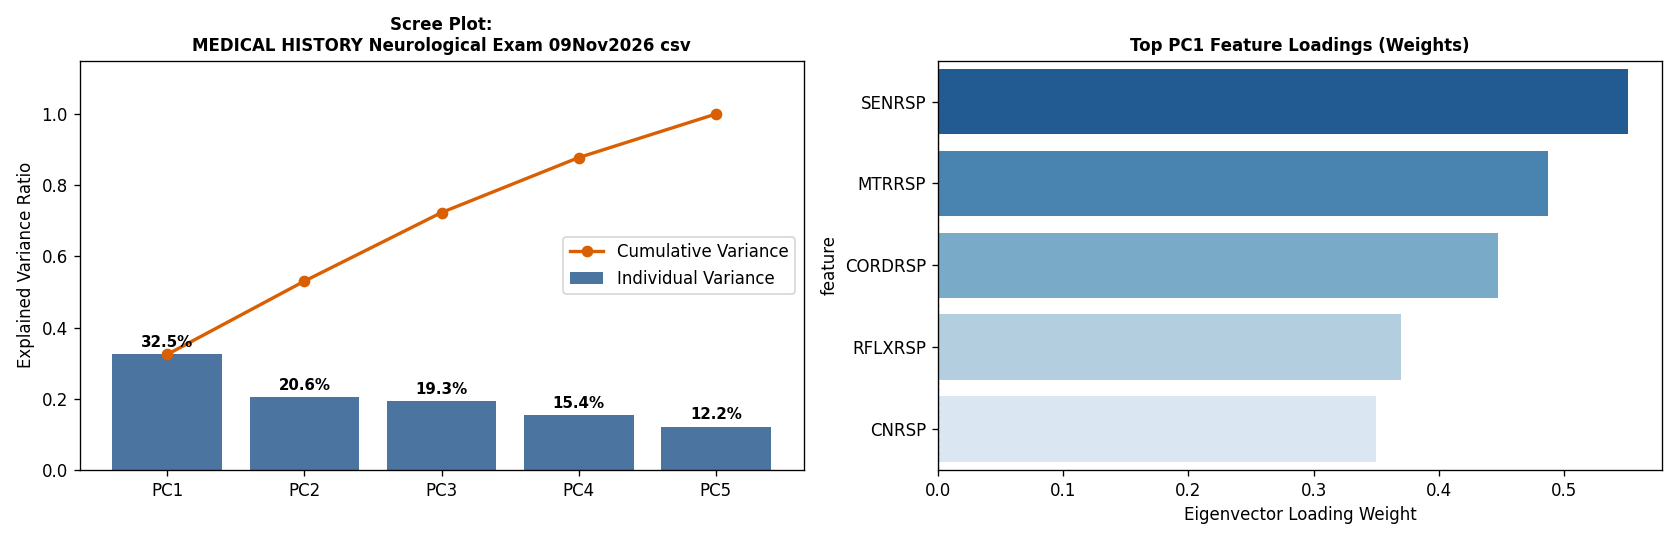

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


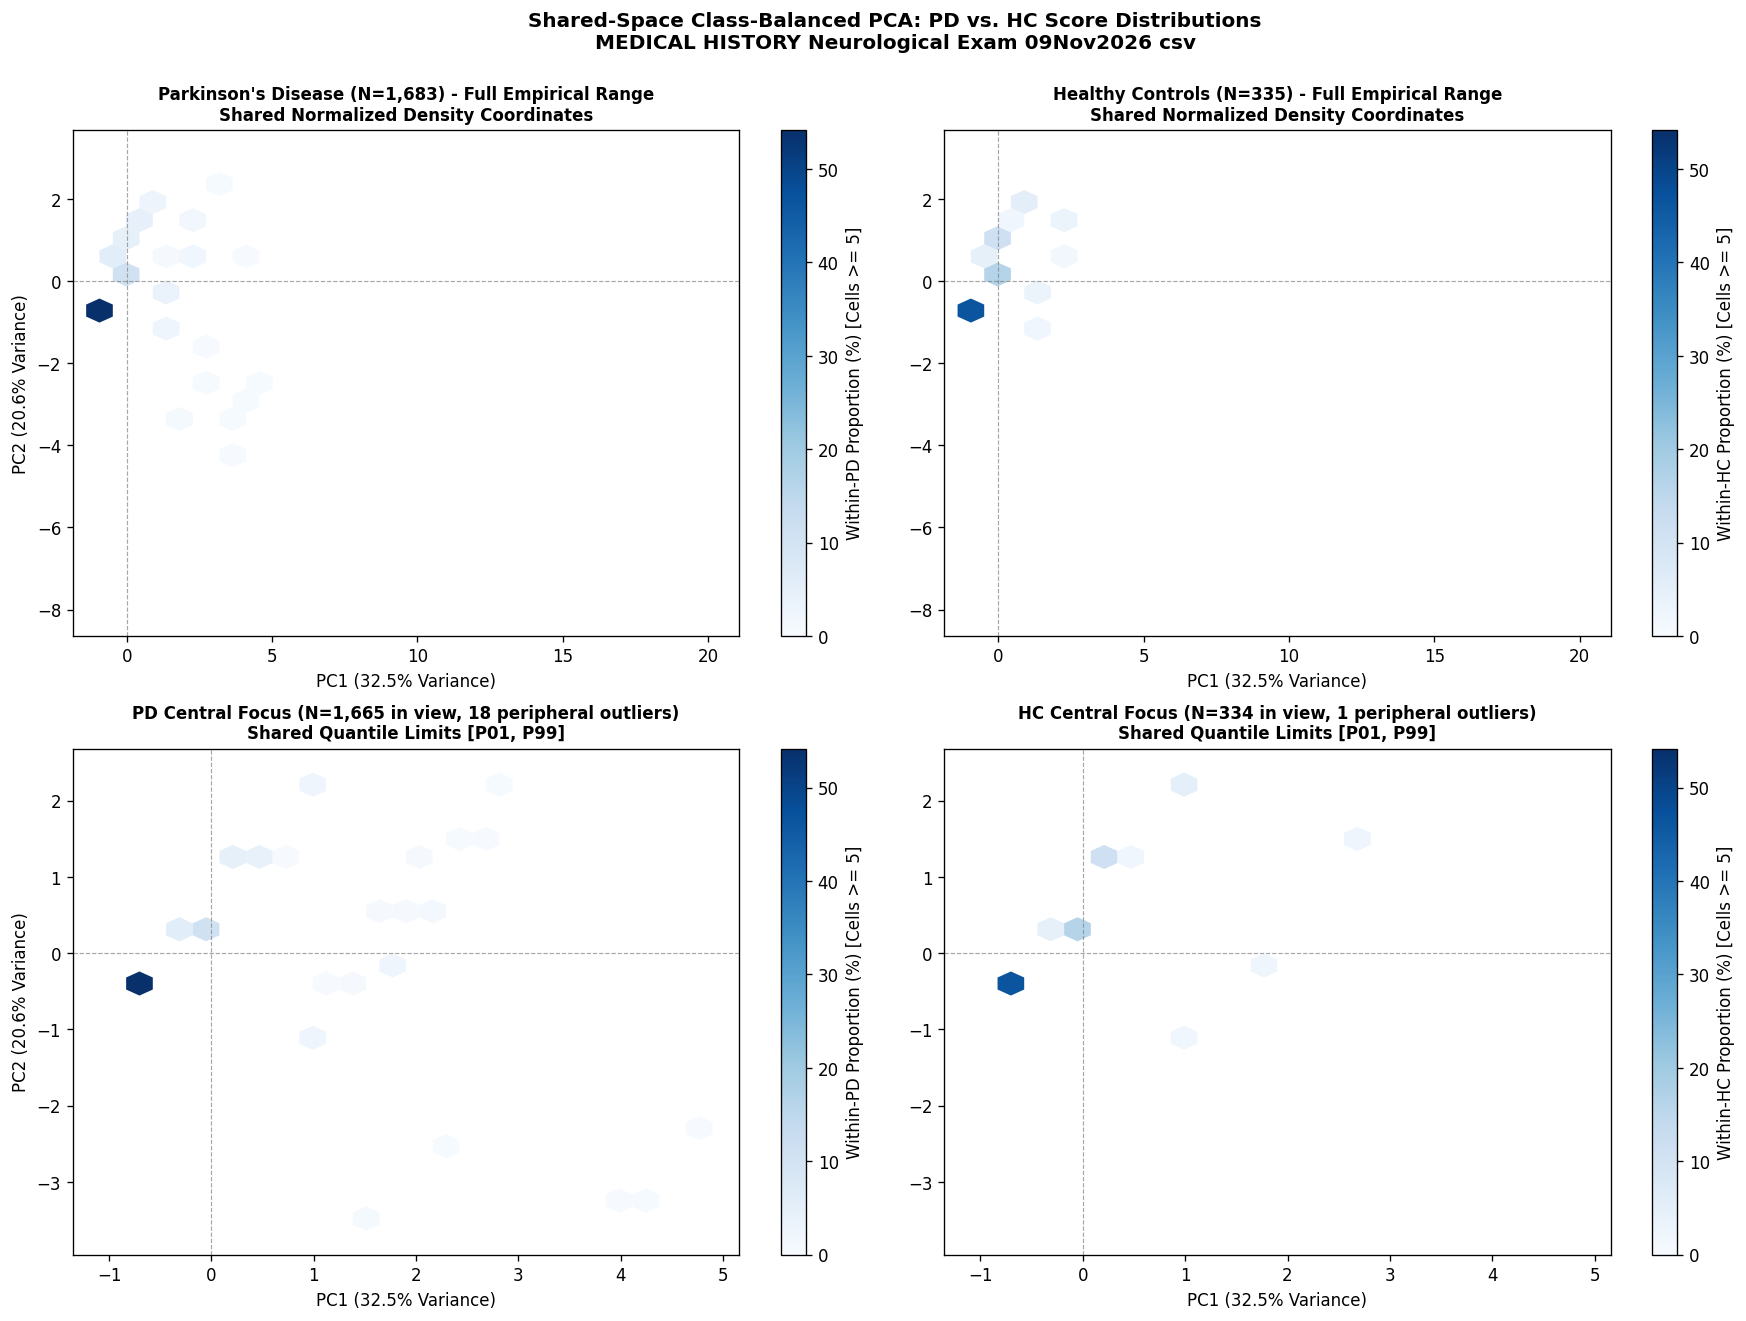

In [20]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/MEDICAL_HISTORY_Neurological_Exam_09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/MEDICAL_HISTORY_Neurological_Exam_09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 3. Modality Synthesis & Scientific Limitations

### Evidence-Bounded Findings
- **Data Coverage**: Analysis covered all 9 scoped analyzable unit(s) belonging to `Medical History, Diagnostics & Medications`.
- **Shared Coordinate Space**: All participant-level PCAs were estimated in a deterministically balanced coordinate space combining Parkinson's disease and healthy control cohorts, which reduces direct sample-count influence on component orientation.
- **Variance Patterns**: Scree and loading structures demonstrate dominant sources of numeric variance within the retained continuous feature space for this modality.

### Methodological Limitations
1. **Unadjusted Covariates**: PCA projections represent unadjusted variance; age, sex, and disease duration effects are not regressed out.
2. **Missingness Imputation**: Median imputation fitted exclusively on the class-balanced training sample was applied to replace missing values in retained features (features with > 40% missingness excluded), preserving sample size rather than performing complete-case deletion.
3. **No Causal / Diagnostic Claims**: PCA scores reflect descriptive data geometry and must not be interpreted as validated diagnostic classifiers or clinical progression endpoints without formal hypothesis testing.